## Прогнозные значения и 95% доверительные интервалы
|   Прогнозный год |   Прогнозное значение (руб.) |   Нижняя граница 95% ДИ (руб.) |   Верхняя граница 95% ДИ (руб.) |
|-----------------:|-----------------------------:|-------------------------------:|--------------------------------:|
|             2024 |                         3.31 |                           1.29 |                            5.34 |
|             2025 |                         2.88 |                           0.41 |                            5.36 |
|             2026 |                         2.41 |                          -0.69 |                            5.5  |


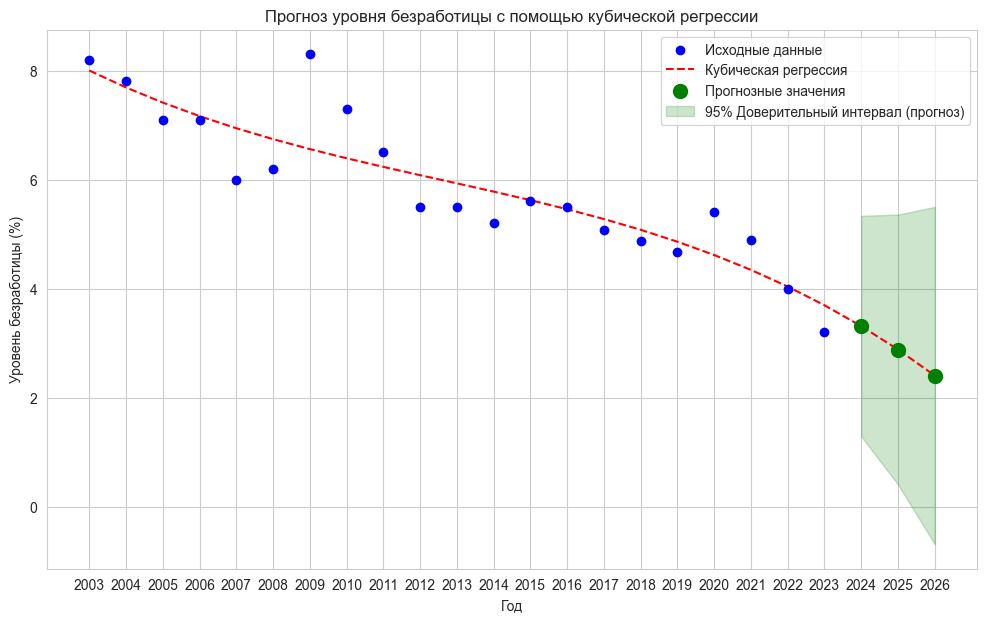

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
import matplotlib.pyplot as plt
import seaborn as sns

# Данные
years_original = np.array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
years_relative = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
unemployment_rates = np.array([8.19, 7.8, 7.1, 7.1, 6.0, 6.2, 8.3, 7.3, 6.5, 5.5, 5.5, 5.2, 5.6, 5.5, 5.071758242, 4.873802198, 4.675846154, 5.4, 4.9, 4.0, 3.2])

# Создание полиномиальных признаков для statsmodels (включая константу)
X = pd.DataFrame({'X': years_relative})
X['X^2'] = X['X']**2
X['X^3'] = X['X']**3
X = sm.add_constant(X) # Добавляем константу для свободного члена

# Обучение модели OLS (Ordinary Least Squares)
model = OLS(unemployment_rates, X)
results = model.fit()

# Прогнозные годы (относительные)
forecast_years_relative = np.array([21, 22, 23]) # 2024, 2025, 2026

# Создание полиномиальных признаков для прогнозных годов
X_forecast = pd.DataFrame({'X': forecast_years_relative})
X_forecast['X^2'] = X_forecast['X']**2
X_forecast['X^3'] = X_forecast['X']**3
X_forecast = sm.add_constant(X_forecast) # Добавляем константу

# Получение прогнозов и доверительных интервалов
predictions = results.get_prediction(X_forecast)
summary_frame = predictions.summary_frame(alpha=0.05) # 95% доверительный интервал (alpha=0.05)

forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Годы для таблицы
forecast_actual_years = [2024, 2025, 2026]

# Вывод таблицы
forecast_table = pd.DataFrame({
    'Прогнозный год': forecast_actual_years,
    'Прогнозное значение (руб.)': forecast_values,
    'Нижняя граница 95% ДИ (руб.)': lower_bound_forecast,
    'Верхняя граница 95% ДИ (руб.)': upper_bound_forecast
})

print("## Прогнозные значения и 95% доверительные интервалы")
print(forecast_table.round(2).to_markdown(index=False))

# Извлечение данных для графика
forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Объединяем исходные и прогнозные годы для оси X на графике
all_years = np.concatenate((years_original, np.array([2024, 2025, 2026])))
all_years_relative = np.concatenate((years_relative, forecast_years_relative))

# Получаем предсказанные значения для всего диапазона данных (для линии регрессии)
# Мы создаем полиномиальные признаки для всего диапазона относительных годов
X_all = pd.DataFrame({'X': all_years_relative})
X_all['X^2'] = X_all['X']**2
X_all['X^3'] = X_all['X']**3
X_all = sm.add_constant(X_all)
predicted_unemployment_all = results.predict(X_all)


# Построение графика
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Исходные данные
plt.scatter(years_original, unemployment_rates, label='Исходные данные', color='blue', zorder=5)

# Линия кубической регрессии (проходящая через исходные и прогнозные точки)
plt.plot(all_years, predicted_unemployment_all, color='red', linestyle='--', label='Кубическая регрессия')

# Прогнозные точки
plt.scatter([2024, 2025, 2026], forecast_values, label='Прогнозные значения', color='green', marker='o', s=100, zorder=5)

# Доверительный интервал для прогноза
plt.fill_between([2024, 2025, 2026], lower_bound_forecast, upper_bound_forecast, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.title('Прогноз уровня безработицы с помощью кубической регрессии')
plt.xlabel('Год')
plt.ylabel('Уровень безработицы (%)')
plt.xticks(all_years) # Чтобы отображать все года на оси X
plt.legend()
plt.grid(True)
plt.show()

## Прогнозные значения и 95% доверительные интервалы
                Прогнозное значение (руб.)  Нижняя граница 95% ДИ (руб.)  \
Прогнозный год                                                             
2024                             234508.05                     213215.94   
2025                             264717.84                     238676.38   
2026                             298958.90                     266417.83   

                Верхняя граница 95% ДИ (руб.)  
Прогнозный год                                 
2024                                255800.16  
2025                                290759.30  
2026                                331499.98  


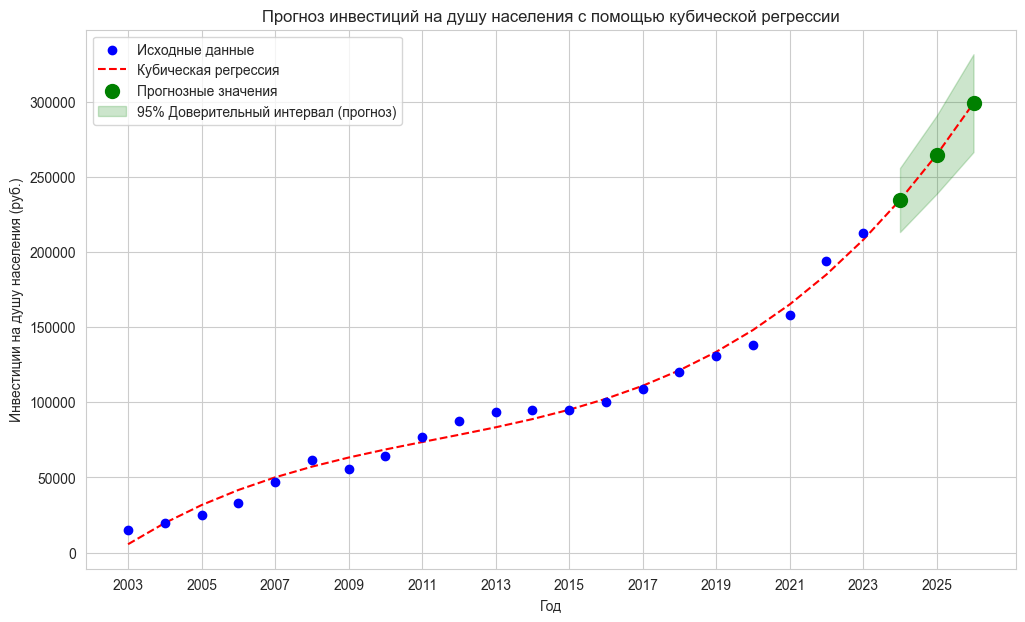


## Анализ прогноза
В 2024 году прогнозируется уровень инвестиций в 234508.05 руб., что составляет абсолютное изменение на 22045.05 руб., или рост на 10.38% по сравнению с 2023 годом. В 2025 году прогнозируется уровень инвестиций в 264717.84 руб., что составляет абсолютное изменение на 52254.84 руб., или рост на 24.59% по сравнению с 2023 годом. В 2026 году прогнозируется уровень инвестиций в 298958.90 руб., что составляет абсолютное изменение на 86495.90 руб., или рост на 40.71% по сравнению с 2023 годом. 


In [17]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
import matplotlib.pyplot as plt
import seaborn as sns

# Данные
years_original = np.array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
years_relative = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
investments = np.array([15114.99, 19886.59, 25160.99, 33065.6, 47030.7, 61520.99, 55860, 64068, 77162.6, 87782.3, 93530.69, 94893.3, 94562.4, 100072.79, 108521, 120295.9, 130689.89, 138068.4, 157857.89, 193669, 212463])

# Создание полиномиальных признаков для statsmodels (включая константу)
X = pd.DataFrame({'X': years_relative})
X['X^2'] = X['X']**2
X['X^3'] = X['X']**3
X = sm.add_constant(X) # Добавляем константу для свободного члена

# Обучение модели OLS (Ordinary Least Squares)
model = OLS(investments, X)
results = model.fit()

# Прогнозные годы (относительные)
forecast_years_relative = np.array([21, 22, 23]) # 2024, 2025, 2026

# Создание полиномиальных признаков для прогнозных годов
X_forecast = pd.DataFrame({'X': forecast_years_relative})
X_forecast['X^2'] = X_forecast['X']**2
X_forecast['X^3'] = X_forecast['X']**3
X_forecast = sm.add_constant(X_forecast) # Добавляем константу

# Получение прогнозов и доверительных интервалов
predictions = results.get_prediction(X_forecast)
summary_frame = predictions.summary_frame(alpha=0.05) # 95% доверительный интервал (alpha=0.05)

# Извлечение данных для графика
forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Годы для таблицы
forecast_actual_years = [2024, 2025, 2026]

# Вывод таблицы
forecast_table = pd.DataFrame({
    'Прогнозный год': forecast_actual_years,
    'Прогнозное значение (руб.)': forecast_values,
    'Нижняя граница 95% ДИ (руб.)': lower_bound_forecast,
    'Верхняя граница 95% ДИ (руб.)': upper_bound_forecast
})

print("## Прогнозные значения и 95% доверительные интервалы")
print(forecast_table.round(2).set_index("Прогнозный год"))

# Объединяем исходные и прогнозные годы для оси X на графике
all_years = np.concatenate((years_original, np.array([2024, 2025, 2026])))
all_years_relative = np.concatenate((years_relative, forecast_years_relative))

# Получаем предсказанные значения для всего диапазона данных (для линии регрессии)
X_all = pd.DataFrame({'X': all_years_relative})
X_all['X^2'] = X_all['X']**2
X_all['X^3'] = X_all['X']**3
X_all = sm.add_constant(X_all)
predicted_investments_all = results.predict(X_all)

# Построение графика
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Исходные данные
plt.scatter(years_original, investments, label='Исходные данные', color='blue', zorder=5)

# Линия кубической регрессии (проходящая через исходные и прогнозные точки)
plt.plot(all_years, predicted_investments_all, color='red', linestyle='--', label='Кубическая регрессия')

# Прогнозные точки
plt.scatter([2024, 2025, 2026], forecast_values, label='Прогнозные значения', color='green', marker='o', s=100, zorder=5)

# Доверительный интервал для прогноза
plt.fill_between([2024, 2025, 2026], lower_bound_forecast, upper_bound_forecast, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.title('Прогноз инвестиций на душу населения с помощью кубической регрессии')
plt.xlabel('Год')
plt.ylabel('Инвестиции на душу населения (руб.)')
plt.xticks(all_years[::2]) # Чтобы не было слишком много меток на оси X
plt.ticklabel_format(style='plain', axis='y') # Отключить научную нотацию для оси Y
plt.legend()
plt.grid(True)
plt.show()

# Анализ
last_original_value = investments[-1]
analysis_text = ""
for i, year in enumerate(forecast_actual_years):
    forecast_val = forecast_values.iloc[i]
    absolute_change = forecast_val - last_original_value
    percentage_change = (absolute_change / last_original_value) * 100
    
    analysis_text += f"В {year} году прогнозируется уровень инвестиций в {forecast_val:.2f} руб., что составляет абсолютное изменение на {absolute_change:.2f} руб., или {'рост' if percentage_change > 0 else 'падение'} на {abs(percentage_change):.2f}% по сравнению с 2023 годом. "

print("\n## Анализ прогноза")
print(analysis_text)

In [3]:
!pip install tabulate


[notice] A new release of pip is available: 25.0 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


## Прогнозные значения и 95% доверительные интервалы
|   Прогнозный год |   Прогнозное значение (%) |   Нижняя граница 95% ДИ (%) |   Верхняя граница 95% ДИ (%) |
|-----------------:|--------------------------:|----------------------------:|-----------------------------:|
|             2024 |                      7.94 |                        5.55 |                        10.32 |
|             2025 |                      6.07 |                        3.15 |                         9    |
|             2026 |                      3.8  |                        0.15 |                         7.45 |


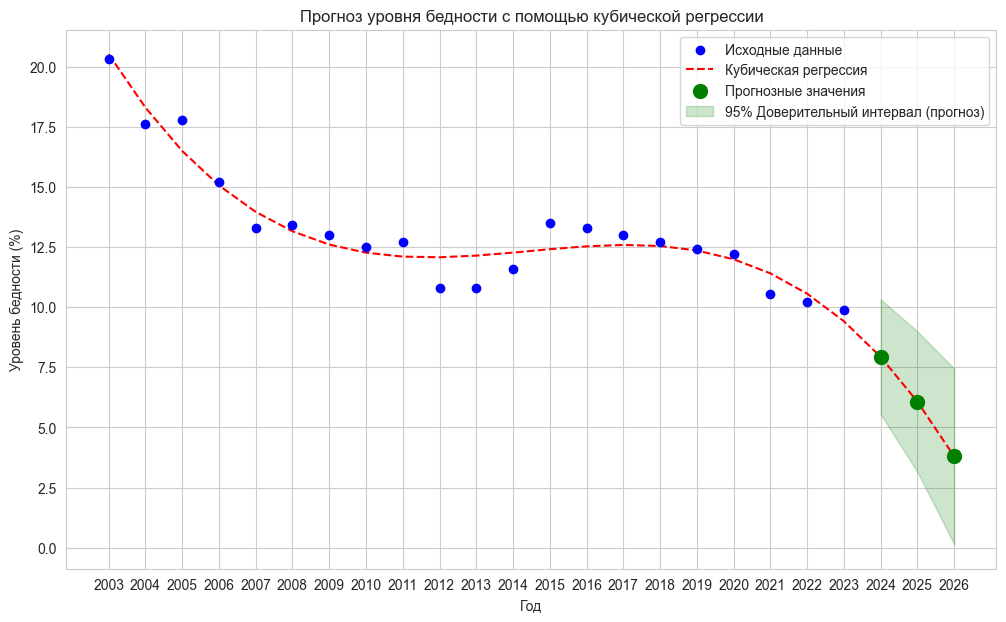


## Анализ прогноза
В 2024 году прогнозируется уровень бедности в 7.94%, что составляет абсолютное изменение на -1.95 процентных пункта, или снижение на 19.69% по сравнению с 2023 годом. В 2025 году прогнозируется уровень бедности в 6.07%, что составляет абсолютное изменение на -3.81 процентных пункта, или снижение на 38.52% по сравнению с 2023 годом. В 2026 году прогнозируется уровень бедности в 3.80%, что составляет абсолютное изменение на -6.08 процентных пункта, или снижение на 61.57% по сравнению с 2023 годом. 


In [5]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
import matplotlib.pyplot as plt
import seaborn as sns

# Данные
years_original = np.array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
years_relative = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
poverty_rates = np.array([20.3, 17.6, 17.8, 15.2, 13.3, 13.4, 13.0, 12.5, 12.7, 10.8, 10.8, 11.6, 13.5, 13.3, 13.0, 12.7, 12.4, 12.2, 10.53986928, 10.21014792, 9.880426557])

# Создание полиномиальных признаков для statsmodels (включая константу)
X = pd.DataFrame({'X': years_relative})
X['X^2'] = X['X']**2
X['X^3'] = X['X']**3
X = sm.add_constant(X) # Добавляем константу для свободного члена

# Обучение модели OLS (Ordinary Least Squares)
model = OLS(poverty_rates, X)
results = model.fit()

# Прогнозные годы (относительные)
forecast_years_relative = np.array([21, 22, 23]) # 2024, 2025, 2026

# Создание полиномиальных признаков для прогнозных годов
X_forecast = pd.DataFrame({'X': forecast_years_relative})
X_forecast['X^2'] = X_forecast['X']**2
X_forecast['X^3'] = X_forecast['X']**3
X_forecast = sm.add_constant(X_forecast) # Добавляем константу

# Получение прогнозов и доверительных интервалов
predictions = results.get_prediction(X_forecast)
summary_frame = predictions.summary_frame(alpha=0.05) # 95% доверительный интервал (alpha=0.05)

# Извлечение данных для графика
forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Годы для таблицы
forecast_actual_years = [2024, 2025, 2026]

# Вывод таблицы
forecast_table = pd.DataFrame({
    'Прогнозный год': forecast_actual_years,
    'Прогнозное значение (%)': forecast_values,
    'Нижняя граница 95% ДИ (%)': lower_bound_forecast,
    'Верхняя граница 95% ДИ (%)': upper_bound_forecast
})

print("## Прогнозные значения и 95% доверительные интервалы")
print(forecast_table.round(2).to_markdown(index=False))

# Объединяем исходные и прогнозные годы для оси X на графике
all_years = np.concatenate((years_original, np.array([2024, 2025, 2026])))
all_years_relative = np.concatenate((years_relative, forecast_years_relative))

# Получаем предсказанные значения для всего диапазона данных (для линии регрессии)
X_all = pd.DataFrame({'X': all_years_relative})
X_all['X^2'] = X_all['X']**2
X_all['X^3'] = X_all['X']**3
X_all = sm.add_constant(X_all)
predicted_poverty_all = results.predict(X_all)

# Построение графика
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Исходные данные
plt.scatter(years_original, poverty_rates, label='Исходные данные', color='blue', zorder=5)

# Линия кубической регрессии (проходящая через исходные и прогнозные точки)
plt.plot(all_years, predicted_poverty_all, color='red', linestyle='--', label='Кубическая регрессия')

# Прогнозные точки
plt.scatter([2024, 2025, 2026], forecast_values, label='Прогнозные значения', color='green', marker='o', s=100, zorder=5)

# Доверительный интервал для прогноза
plt.fill_between([2024, 2025, 2026], lower_bound_forecast, upper_bound_forecast, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.title('Прогноз уровня бедности с помощью кубической регрессии')
plt.xlabel('Год')
plt.ylabel('Уровень бедности (%)')
plt.xticks(all_years) # Чтобы отображать все года на оси X
plt.legend()
plt.grid(True)
plt.show()

# Анализ
last_original_value = poverty_rates[-1]
analysis_text = ""
for i, year in enumerate(forecast_actual_years):
    forecast_val = forecast_values.iloc[i]
    absolute_change = forecast_val - last_original_value
    percentage_change = (absolute_change / last_original_value) * 100
    
    analysis_text += f"В {year} году прогнозируется уровень бедности в {forecast_val:.2f}%, что составляет абсолютное изменение на {absolute_change:.2f} процентных пункта, или {'рост' if percentage_change > 0 else 'снижение'} на {abs(percentage_change):.2f}% по сравнению с 2023 годом. "

print("\n## Анализ прогноза")
print(analysis_text)

## Прогнозные значения и 95% доверительные интервалы
|   Прогнозный год |   Прогнозное значение (промилле) |   Нижняя граница 95% ДИ (промилле) |   Верхняя граница 95% ДИ (промилле) |
|-----------------:|---------------------------------:|-----------------------------------:|------------------------------------:|
|             2024 |                            -6.84 |                             -10.66 |                               -3.02 |
|             2025 |                            -8.08 |                             -12.75 |                               -3.4  |
|             2026 |                            -9.42 |                             -15.26 |                               -3.58 |


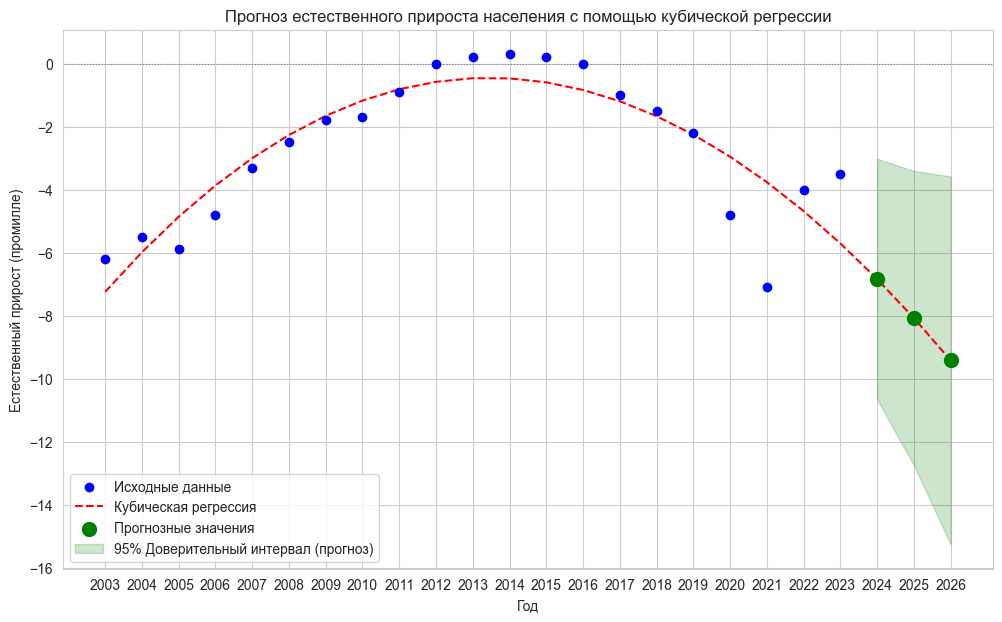


## Анализ прогноза
В 2024 году прогнозируется естественный прирост в -6.84 промилле, что составляет абсолютное изменение на -3.34 промилле, или рост на 95.42% по сравнению с 2023 годом. В 2025 году прогнозируется естественный прирост в -8.08 промилле, что составляет абсолютное изменение на -4.58 промилле, или рост на 130.80% по сравнению с 2023 годом. В 2026 году прогнозируется естественный прирост в -9.42 промилле, что составляет абсолютное изменение на -5.92 промилле, или рост на 169.15% по сравнению с 2023 годом. 


In [6]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
import matplotlib.pyplot as plt
import seaborn as sns

# Данные
years_original = np.array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
years_relative = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
natural_growth = np.array([-6.2, -5.5, -5.9, -4.8, -3.3, -2.5, -1.8, -1.7, -0.9, 0.0, 0.2, 0.3, 0.2, 0.0, -1.0, -1.5, -2.21, -4.8, -7.1, -4.0, -3.5])

# Создание полиномиальных признаков для statsmodels (включая константу)
X = pd.DataFrame({'X': years_relative})
X['X^2'] = X['X']**2
X['X^3'] = X['X']**3
X = sm.add_constant(X) # Добавляем константу для свободного члена

# Обучение модели OLS (Ordinary Least Squares)
model = OLS(natural_growth, X)
results = model.fit()

# Прогнозные годы (относительные)
forecast_years_relative = np.array([21, 22, 23]) # 2024, 2025, 2026

# Создание полиномиальных признаков для прогнозных годов
X_forecast = pd.DataFrame({'X': forecast_years_relative})
X_forecast['X^2'] = X_forecast['X']**2
X_forecast['X^3'] = X_forecast['X']**3
X_forecast = sm.add_constant(X_forecast) # Добавляем константу

# Получение прогнозов и доверительных интервалов
predictions = results.get_prediction(X_forecast)
summary_frame = predictions.summary_frame(alpha=0.05) # 95% доверительный интервал (alpha=0.05)

# Извлечение данных для графика
forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Годы для таблицы
forecast_actual_years = [2024, 2025, 2026]

# Вывод таблицы
forecast_table = pd.DataFrame({
    'Прогнозный год': forecast_actual_years,
    'Прогнозное значение (промилле)': forecast_values,
    'Нижняя граница 95% ДИ (промилле)': lower_bound_forecast,
    'Верхняя граница 95% ДИ (промилле)': upper_bound_forecast
})

print("## Прогнозные значения и 95% доверительные интервалы")
print(forecast_table.round(2).to_markdown(index=False))

# Объединяем исходные и прогнозные годы для оси X на графике
all_years = np.concatenate((years_original, np.array([2024, 2025, 2026])))
all_years_relative = np.concatenate((years_relative, forecast_years_relative))

# Получаем предсказанные значения для всего диапазона данных (для линии регрессии)
X_all = pd.DataFrame({'X': all_years_relative})
X_all['X^2'] = X_all['X']**2
X_all['X^3'] = X_all['X']**3
X_all = sm.add_constant(X_all)
predicted_natural_growth_all = results.predict(X_all)

# Построение графика
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Исходные данные
plt.scatter(years_original, natural_growth, label='Исходные данные', color='blue', zorder=5)

# Линия кубической регрессии (проходящая через исходные и прогнозные точки)
plt.plot(all_years, predicted_natural_growth_all, color='red', linestyle='--', label='Кубическая регрессия')

# Прогнозные точки
plt.scatter([2024, 2025, 2026], forecast_values, label='Прогнозные значения', color='green', marker='o', s=100, zorder=5)

# Доверительный интервал для прогноза
plt.fill_between([2024, 2025, 2026], lower_bound_forecast, upper_bound_forecast, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.title('Прогноз естественного прироста населения с помощью кубической регрессии')
plt.xlabel('Год')
plt.ylabel('Естественный прирост (промилле)')
plt.xticks(all_years) # Чтобы отображать все года на оси X
plt.legend()
plt.grid(True)
plt.axhline(0, color='gray', linestyle=':', linewidth=0.8) # Линия нулевого прироста
plt.show()

# Анализ
last_original_value = natural_growth[-1]
analysis_text = ""
for i, year in enumerate(forecast_actual_years):
    forecast_val = forecast_values.iloc[i]
    absolute_change = forecast_val - last_original_value
    
    # Избегаем деления на ноль или очень малые значения, которые могут привести к огромным процентам
    if abs(last_original_value) > 1e-6: # Если значение не близко к нулю
        percentage_change = (absolute_change / last_original_value) * 100
        change_desc = f"{'рост' if percentage_change > 0 else 'снижение'} на {abs(percentage_change):.2f}%"
    else: # Если последнее значение близко к нулю, процентное изменение не имеет смысла
        change_desc = "изменение в процентах не применимо из-за близости исходного значения к нулю"

    analysis_text += f"В {year} году прогнозируется естественный прирост в {forecast_val:.2f} промилле, что составляет абсолютное изменение на {absolute_change:.2f} промилле, или {change_desc} по сравнению с 2023 годом. "

print("\n## Анализ прогноза")
print(analysis_text)

## Прогнозные значения и 95% доверительные интервалы
|   Прогнозный год |   Прогнозное значение (чел.) |   Нижняя граница 95% ДИ (чел.) |   Верхняя граница 95% ДИ (чел.) |
|-----------------:|-----------------------------:|-------------------------------:|--------------------------------:|
|             2024 |                         9.01 |                         -11.44 |                           29.46 |
|             2025 |                         4.61 |                         -20.4  |                           29.62 |
|             2026 |                        -0.36 |                         -31.62 |                           30.89 |


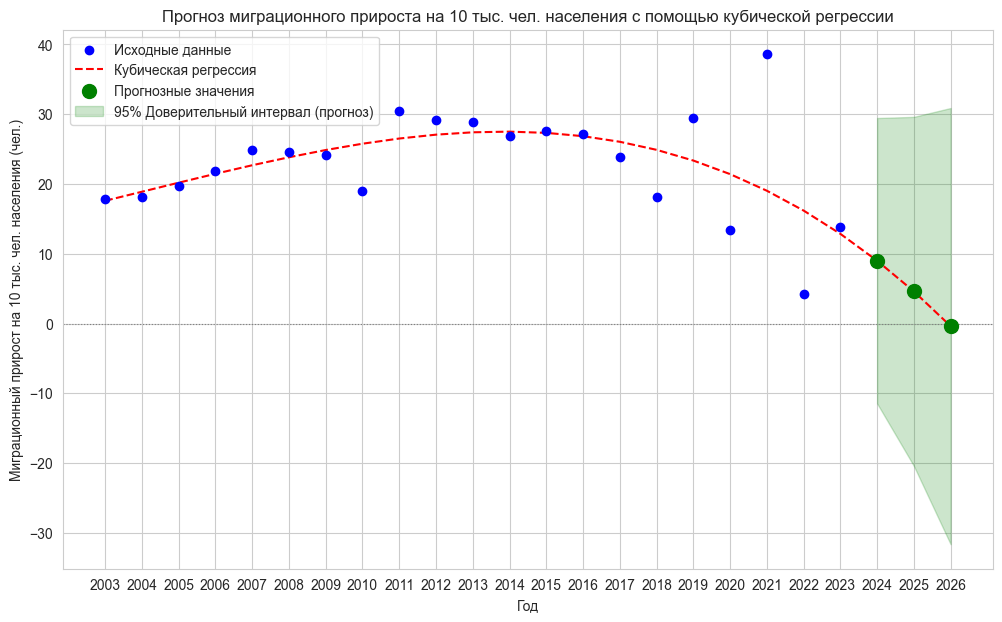


## Анализ прогноза
В 2024 году прогнозируется миграционный прирост в 9.01 чел., что составляет абсолютное изменение на -4.89 чел., или снижение на 35.20% по сравнению с 2023 годом. В 2025 году прогнозируется миграционный прирост в 4.61 чел., что составляет абсолютное изменение на -9.29 чел., или снижение на 66.84% по сравнению с 2023 годом. В 2026 году прогнозируется миграционный прирост в -0.36 чел., что составляет абсолютное изменение на -14.26 чел., или снижение на 102.62% по сравнению с 2023 годом. 


In [7]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
import matplotlib.pyplot as plt
import seaborn as sns

# Данные
years_original = np.array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
years_relative = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
migration_growth = np.array([17.86, 18.07, 19.65, 21.89, 24.87, 24.63, 24.17, 19.0, 30.4, 29.2, 28.9, 26.9, 27.6, 27.1, 23.9, 18.1, 29.5, 13.4, 38.6, 4.2, 13.9])

# Создание полиномиальных признаков для statsmodels (включая константу)
X = pd.DataFrame({'X': years_relative})
X['X^2'] = X['X']**2
X['X^3'] = X['X']**3
X = sm.add_constant(X) # Добавляем константу для свободного члена

# Обучение модели OLS (Ordinary Least Squares)
model = OLS(migration_growth, X)
results = model.fit()

# Прогнозные годы (относительные)
forecast_years_relative = np.array([21, 22, 23]) # 2024, 2025, 2026

# Создание полиномиальных признаков для прогнозных годов
X_forecast = pd.DataFrame({'X': forecast_years_relative})
X_forecast['X^2'] = X_forecast['X']**2
X_forecast['X^3'] = X_forecast['X']**3
X_forecast = sm.add_constant(X_forecast) # Добавляем константу

# Получение прогнозов и доверительных интервалов
predictions = results.get_prediction(X_forecast)
summary_frame = predictions.summary_frame(alpha=0.05) # 95% доверительный интервал (alpha=0.05)

# Извлечение данных для графика
forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Годы для таблицы
forecast_actual_years = [2024, 2025, 2026]

# Вывод таблицы
forecast_table = pd.DataFrame({
    'Прогнозный год': forecast_actual_years,
    'Прогнозное значение (чел.)': forecast_values,
    'Нижняя граница 95% ДИ (чел.)': lower_bound_forecast,
    'Верхняя граница 95% ДИ (чел.)': upper_bound_forecast
})

print("## Прогнозные значения и 95% доверительные интервалы")
print(forecast_table.round(2).to_markdown(index=False))

# Объединяем исходные и прогнозные годы для оси X на графике
all_years = np.concatenate((years_original, np.array([2024, 2025, 2026])))
all_years_relative = np.concatenate((years_relative, forecast_years_relative))

# Получаем предсказанные значения для всего диапазона данных (для линии регрессии)
X_all = pd.DataFrame({'X': all_years_relative})
X_all['X^2'] = X_all['X']**2
X_all['X^3'] = X_all['X']**3
X_all = sm.add_constant(X_all)
predicted_migration_all = results.predict(X_all)

# Построение графика
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Исходные данные
plt.scatter(years_original, migration_growth, label='Исходные данные', color='blue', zorder=5)

# Линия кубической регрессии (проходящая через исходные и прогнозные точки)
plt.plot(all_years, predicted_migration_all, color='red', linestyle='--', label='Кубическая регрессия')

# Прогнозные точки
plt.scatter([2024, 2025, 2026], forecast_values, label='Прогнозные значения', color='green', marker='o', s=100, zorder=5)

# Доверительный интервал для прогноза
plt.fill_between([2024, 2025, 2026], lower_bound_forecast, upper_bound_forecast, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.title('Прогноз миграционного прироста на 10 тыс. чел. населения с помощью кубической регрессии')
plt.xlabel('Год')
plt.ylabel('Миграционный прирост на 10 тыс. чел. населения (чел.)')
plt.xticks(all_years) # Чтобы отображать все года на оси X
plt.legend()
plt.grid(True)
plt.axhline(0, color='gray', linestyle=':', linewidth=0.8) # Линия нулевого прироста/убыли
plt.show()

# Анализ
last_original_value = migration_growth[-1]
analysis_text = ""
for i, year in enumerate(forecast_actual_years):
    forecast_val = forecast_values.iloc[i]
    absolute_change = forecast_val - last_original_value
    
    # Избегаем деления на ноль или очень малые значения, которые могут привести к огромным процентам
    if abs(last_original_value) > 1e-6: # Если значение не близко к нулю
        percentage_change = (absolute_change / last_original_value) * 100
        change_desc = f"{'рост' if percentage_change > 0 else 'снижение'} на {abs(percentage_change):.2f}%"
    else: # Если последнее значение близко к нулю, процентное изменение не имеет смысла
        change_desc = "изменение в процентах не применимо из-за близости исходного значения к нулю"

    analysis_text += f"В {year} году прогнозируется миграционный прирост в {forecast_val:.2f} чел., что составляет абсолютное изменение на {absolute_change:.2f} чел., или {change_desc} по сравнению с 2023 годом. "

print("\n## Анализ прогноза")
print(analysis_text)

## Прогнозные значения и 95% доверительные интервалы
|   Прогнозный год |   Прогнозное значение (%) |   Нижняя граница 95% ДИ (%) |   Верхняя граница 95% ДИ (%) |
|-----------------:|--------------------------:|----------------------------:|-----------------------------:|
|             2024 |                    101    |                       93.25 |                       108.76 |
|             2025 |                    101.02 |                       91.54 |                       110.5  |
|             2026 |                    101.06 |                       89.21 |                       112.9  |


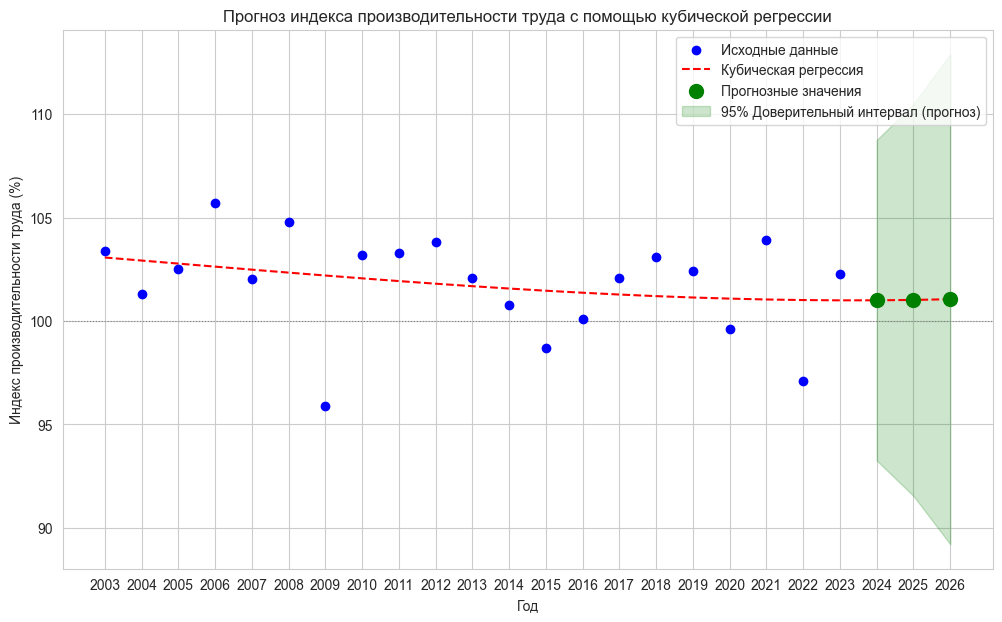


## Анализ прогноза
В 2024 году прогнозируется индекс производительности труда в 101.00%, что составляет абсолютное изменение на -1.30 процентных пункта, или снижение на 1.27% по сравнению с 2023 годом. В 2025 году прогнозируется индекс производительности труда в 101.02%, что составляет абсолютное изменение на -1.28 процентных пункта, или снижение на 1.25% по сравнению с 2023 годом. В 2026 году прогнозируется индекс производительности труда в 101.06%, что составляет абсолютное изменение на -1.24 процентных пункта, или снижение на 1.22% по сравнению с 2023 годом. 


In [8]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
import matplotlib.pyplot as plt
import seaborn as sns

# Данные
years_original = np.array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
years_relative = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
productivity_index = np.array([103.4, 101.3, 102.5, 105.7, 102.0375, 104.8, 95.9, 103.2, 103.3, 103.8, 102.1, 100.8, 98.7, 100.1, 102.1, 103.1, 102.4, 99.6, 103.9, 97.1, 102.3])

# Создание полиномиальных признаков для statsmodels (включая константу)
X = pd.DataFrame({'X': years_relative})
X['X^2'] = X['X']**2
X['X^3'] = X['X']**3
X = sm.add_constant(X) # Добавляем константу для свободного члена

# Обучение модели OLS (Ordinary Least Squares)
model = OLS(productivity_index, X)
results = model.fit()

# Прогнозные годы (относительные)
forecast_years_relative = np.array([21, 22, 23]) # 2024, 2025, 2026

# Создание полиномиальных признаков для прогнозных годов
X_forecast = pd.DataFrame({'X': forecast_years_relative})
X_forecast['X^2'] = X_forecast['X']**2
X_forecast['X^3'] = X_forecast['X']**3
X_forecast = sm.add_constant(X_forecast) # Добавляем константу

# Получение прогнозов и доверительных интервалов
predictions = results.get_prediction(X_forecast)
summary_frame = predictions.summary_frame(alpha=0.05) # 95% доверительный интервал (alpha=0.05)

# Извлечение данных для графика
forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Годы для таблицы
forecast_actual_years = [2024, 2025, 2026]

# Вывод таблицы
forecast_table = pd.DataFrame({
    'Прогнозный год': forecast_actual_years,
    'Прогнозное значение (%)': forecast_values,
    'Нижняя граница 95% ДИ (%)': lower_bound_forecast,
    'Верхняя граница 95% ДИ (%)': upper_bound_forecast
})

print("## Прогнозные значения и 95% доверительные интервалы")
print(forecast_table.round(2).to_markdown(index=False))

# Объединяем исходные и прогнозные годы для оси X на графике
all_years = np.concatenate((years_original, np.array([2024, 2025, 2026])))
all_years_relative = np.concatenate((years_relative, forecast_years_relative))

# Получаем предсказанные значения для всего диапазона данных (для линии регрессии)
X_all = pd.DataFrame({'X': all_years_relative})
X_all['X^2'] = X_all['X']**2
X_all['X^3'] = X_all['X']**3
X_all = sm.add_constant(X_all)
predicted_productivity_all = results.predict(X_all)

# Построение графика
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Исходные данные
plt.scatter(years_original, productivity_index, label='Исходные данные', color='blue', zorder=5)

# Линия кубической регрессии (проходящая через исходные и прогнозные точки)
plt.plot(all_years, predicted_productivity_all, color='red', linestyle='--', label='Кубическая регрессия')

# Прогнозные точки
plt.scatter([2024, 2025, 2026], forecast_values, label='Прогнозные значения', color='green', marker='o', s=100, zorder=5)

# Доверительный интервал для прогноза
plt.fill_between([2024, 2025, 2026], lower_bound_forecast, upper_bound_forecast, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.title('Прогноз индекса производительности труда с помощью кубической регрессии')
plt.xlabel('Год')
plt.ylabel('Индекс производительности труда (%)')
plt.xticks(all_years) # Чтобы отображать все года на оси X
plt.legend()
plt.grid(True)
plt.axhline(100, color='gray', linestyle=':', linewidth=0.8) # Линия 100% (базовый уровень)
plt.show()

# Анализ
last_original_value = productivity_index[-1]
analysis_text = ""
for i, year in enumerate(forecast_actual_years):
    forecast_val = forecast_values.iloc[i]
    absolute_change = forecast_val - last_original_value
    
    # Избегаем деления на ноль или очень малые значения, которые могут привести к огромным процентам
    if abs(last_original_value) > 1e-6: # Если значение не близко к нулю
        percentage_change = (absolute_change / last_original_value) * 100
        change_desc = f"{'рост' if percentage_change > 0 else 'снижение'} на {abs(percentage_change):.2f}%"
    else: # Если последнее значение близко к нулю, процентное изменение не имеет смысла
        change_desc = "изменение в процентах не применимо из-за близости исходного значения к нулю"

    analysis_text += f"В {year} году прогнозируется индекс производительности труда в {forecast_val:.2f}%, что составляет абсолютное изменение на {absolute_change:.2f} процентных пункта, или {change_desc} по сравнению с 2023 годом. "

print("\n## Анализ прогноза")
print(analysis_text)

## Прогнозные значения и 95% доверительные интервалы
|   Прогнозный год |   Прогнозное значение (руб.) |   Нижняя граница 95% ДИ (руб.) |   Верхняя граница 95% ДИ (руб.) |
|-----------------:|-----------------------------:|-------------------------------:|--------------------------------:|
|             2024 |                       778327 |                         726413 |                          830241 |
|             2025 |                       803225 |                         739731 |                          866719 |
|             2026 |                       825017 |                         745675 |                          904358 |


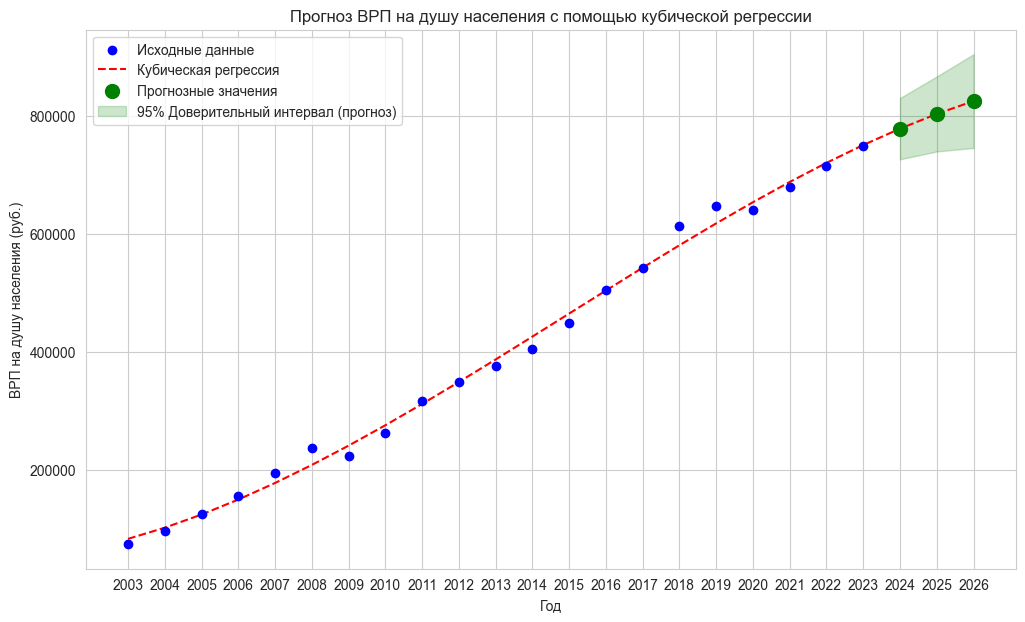


## Анализ прогноза
В 2024 году прогнозируется ВРП на душу населения в 778326.90 руб., что составляет абсолютное изменение на 28907.39 руб., или рост на 3.86% по сравнению с 2023 годом. В 2025 году прогнозируется ВРП на душу населения в 803224.85 руб., что составляет абсолютное изменение на 53805.34 руб., или рост на 7.18% по сравнению с 2023 годом. В 2026 году прогнозируется ВРП на душу населения в 825016.59 руб., что составляет абсолютное изменение на 75597.08 руб., или рост на 10.09% по сравнению с 2023 годом. 


In [10]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
import matplotlib.pyplot as plt
import seaborn as sns

# Данные
years_original = np.array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
years_relative = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
grp_per_capita = np.array([74840.5, 97691.9, 125658.7, 157233.0, 195819.0, 237552.2, 224163.29, 263828.59, 317515.3, 348641.49, 377005.99, 405147.7, 449097.9, 505337.69, 543065.9, 614333.19, 647708.1, 640518.99, 679232.1528, 714325.833, 749419.5133])

# Создание полиномиальных признаков для statsmodels (включая константу)
X = pd.DataFrame({'X': years_relative})
X['X^2'] = X['X']**2
X['X^3'] = X['X']**3
X = sm.add_constant(X) # Добавляем константу для свободного члена

# Обучение модели OLS (Ordinary Least Squares)
model = OLS(grp_per_capita, X)
results = model.fit()

# Прогнозные годы (относительные)
forecast_years_relative = np.array([21, 22, 23]) # 2024, 2025, 2026

# Создание полиномиальных признаков для прогнозных годов
X_forecast = pd.DataFrame({'X': forecast_years_relative})
X_forecast['X^2'] = X_forecast['X']**2
X_forecast['X^3'] = X_forecast['X']**3
X_forecast = sm.add_constant(X_forecast) # Добавляем константу

# Получение прогнозов и доверительных интервалов
predictions = results.get_prediction(X_forecast)
summary_frame = predictions.summary_frame(alpha=0.05) # 95% доверительный интервал (alpha=0.05)

# Извлечение данных для графика
forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Годы для таблицы
forecast_actual_years = [2024, 2025, 2026]

# Вывод таблицы
forecast_table = pd.DataFrame({
    'Прогнозный год': forecast_actual_years,
    'Прогнозное значение (руб.)': forecast_values,
    'Нижняя граница 95% ДИ (руб.)': lower_bound_forecast,
    'Верхняя граница 95% ДИ (руб.)': upper_bound_forecast
})

print("## Прогнозные значения и 95% доверительные интервалы")
print(forecast_table.round(2).to_markdown(index=False))

# Объединяем исходные и прогнозные годы для оси X на графике
all_years = np.concatenate((years_original, np.array([2024, 2025, 2026])))
all_years_relative = np.concatenate((years_relative, forecast_years_relative))

# Получаем предсказанные значения для всего диапазона данных (для линии регрессии)
X_all = pd.DataFrame({'X': all_years_relative})
X_all['X^2'] = X_all['X']**2
X_all['X^3'] = X_all['X']**3
X_all = sm.add_constant(X_all)
predicted_grp_all = results.predict(X_all)

# Построение графика
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Исходные данные
plt.scatter(years_original, grp_per_capita, label='Исходные данные', color='blue', zorder=5)

# Линия кубической регрессии (проходящая через исходные и прогнозные точки)
plt.plot(all_years, predicted_grp_all, color='red', linestyle='--', label='Кубическая регрессия')

# Прогнозные точки
plt.scatter([2024, 2025, 2026], forecast_values, label='Прогнозные значения', color='green', marker='o', s=100, zorder=5)

# Доверительный интервал для прогноза
plt.fill_between([2024, 2025, 2026], lower_bound_forecast, upper_bound_forecast, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.title('Прогноз ВРП на душу населения с помощью кубической регрессии')
plt.xlabel('Год')
plt.ylabel('ВРП на душу населения (руб.)')
plt.xticks(all_years) # Чтобы отображать все года на оси X
plt.ticklabel_format(style='plain', axis='y') # Отключить научную нотацию для оси Y
plt.legend()
plt.grid(True)
plt.show()

# Анализ
last_original_value = grp_per_capita[-1]
analysis_text = ""
for i, year in enumerate(forecast_actual_years):
    forecast_val = forecast_values.iloc[i]
    absolute_change = forecast_val - last_original_value
    
    # Избегаем деления на ноль или очень малые значения, которые могут привести к огромным процентам
    if abs(last_original_value) > 1e-6: # Если значение не близко к нулю
        percentage_change = (absolute_change / last_original_value) * 100
        change_desc = f"{'рост' if percentage_change > 0 else 'снижение'} на {abs(percentage_change):.2f}%"
    else: # Если последнее значение близко к нулю, процентное изменение не имеет смысла
        change_desc = "изменение в процентах не применимо из-за близости исходного значения к нулю"

    analysis_text += f"В {year} году прогнозируется ВРП на душу населения в {forecast_val:.2f} руб., что составляет абсолютное изменение на {absolute_change:.2f} руб., или {change_desc} по сравнению с 2023 годом. "

print("\n## Анализ прогноза")
print(analysis_text)

## Прогнозные значения и 95% доверительные интервалы
|   Прогнозный год |   Прогнозное значение (%) |   Нижняя граница 95% ДИ (%) |   Верхняя граница 95% ДИ (%) |
|-----------------:|--------------------------:|----------------------------:|-----------------------------:|
|             2024 |                     71.21 |                       70.26 |                        72.17 |
|             2025 |                     71.54 |                       70.38 |                        72.71 |
|             2026 |                     71.91 |                       70.46 |                        73.37 |


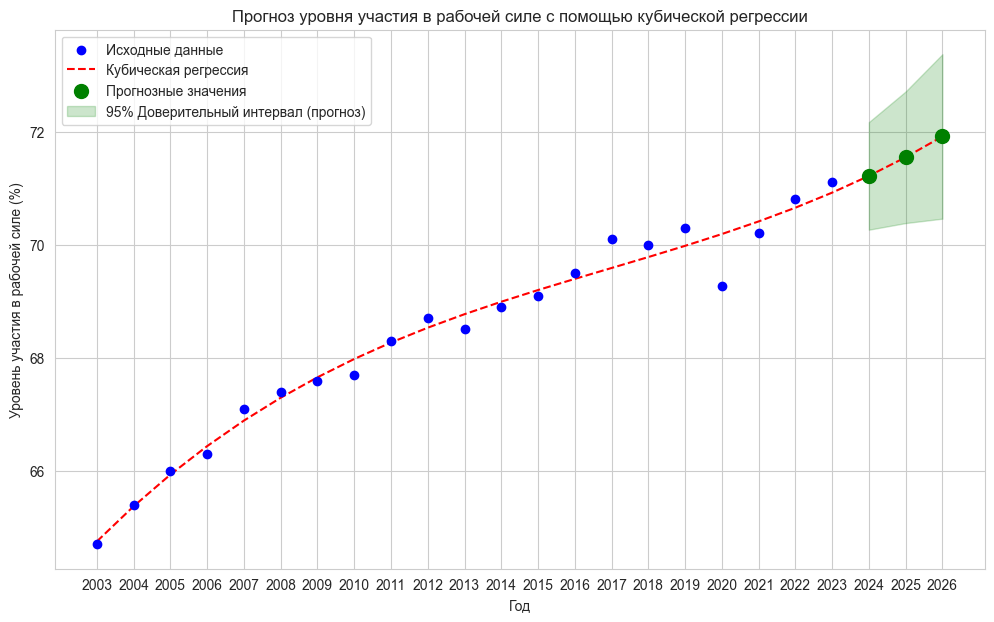


## Анализ прогноза
В 2024 году прогнозируется уровень участия в рабочей силе в 71.21%, что составляет абсолютное изменение на 0.11 процентных пункта, или рост на 0.16% по сравнению с 2023 годом. В 2025 году прогнозируется уровень участия в рабочей силе в 71.54%, что составляет абсолютное изменение на 0.44 процентных пункта, или рост на 0.63% по сравнению с 2023 годом. В 2026 году прогнозируется уровень участия в рабочей силе в 71.91%, что составляет абсолютное изменение на 0.81 процентных пункта, или рост на 1.14% по сравнению с 2023 годом. 


In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
import matplotlib.pyplot as plt
import seaborn as sns

# Данные
years_original = np.array([2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])
years_relative = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
labor_force_participation = np.array([64.7, 65.4, 66.0, 66.3, 67.09, 67.4, 67.59, 67.7, 68.3, 68.7, 68.5, 68.9, 69.09, 69.5, 70.1, 70.0, 70.3, 69.2747327, 70.20589976, 70.8, 71.1])

# Создание полиномиальных признаков для statsmodels (включая константу)
X = pd.DataFrame({'X': years_relative})
X['X^2'] = X['X']**2
X['X^3'] = X['X']**3
X = sm.add_constant(X) # Добавляем константу для свободного члена

# Обучение модели OLS (Ordinary Least Squares)
model = OLS(labor_force_participation, X)
results = model.fit()

# Прогнозные годы (относительные)
forecast_years_relative = np.array([21, 22, 23]) # 2024, 2025, 2026

# Создание полиномиальных признаков для прогнозных годов
X_forecast = pd.DataFrame({'X': forecast_years_relative})
X_forecast['X^2'] = X_forecast['X']**2
X_forecast['X^3'] = X_forecast['X']**3
X_forecast = sm.add_constant(X_forecast) # Добавляем константу

# Получение прогнозов и доверительных интервалов
predictions = results.get_prediction(X_forecast)
summary_frame = predictions.summary_frame(alpha=0.05) # 95% доверительный интервал (alpha=0.05)

# Извлечение данных для графика
forecast_values = summary_frame['mean']
lower_bound_forecast = summary_frame['obs_ci_lower']
upper_bound_forecast = summary_frame['obs_ci_upper']

# Годы для таблицы
forecast_actual_years = [2024, 2025, 2026]

# Вывод таблицы
forecast_table = pd.DataFrame({
    'Прогнозный год': forecast_actual_years,
    'Прогнозное значение (%)': forecast_values,
    'Нижняя граница 95% ДИ (%)': lower_bound_forecast,
    'Верхняя граница 95% ДИ (%)': upper_bound_forecast
})

print("## Прогнозные значения и 95% доверительные интервалы")
print(forecast_table.round(2).to_markdown(index=False))

# Объединяем исходные и прогнозные годы для оси X на графике
all_years = np.concatenate((years_original, np.array([2024, 2025, 2026])))
all_years_relative = np.concatenate((years_relative, forecast_years_relative))

# Получаем предсказанные значения для всего диапазона данных (для линии регрессии)
X_all = pd.DataFrame({'X': all_years_relative})
X_all['X^2'] = X_all['X']**2
X_all['X^3'] = X_all['X']**3
X_all = sm.add_constant(X_all)
predicted_labor_force_all = results.predict(X_all)

# Построение графика
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Исходные данные
plt.scatter(years_original, labor_force_participation, label='Исходные данные', color='blue', zorder=5)

# Линия кубической регрессии (проходящая через исходные и прогнозные точки)
plt.plot(all_years, predicted_labor_force_all, color='red', linestyle='--', label='Кубическая регрессия')

# Прогнозные точки
plt.scatter([2024, 2025, 2026], forecast_values, label='Прогнозные значения', color='green', marker='o', s=100, zorder=5)

# Доверительный интервал для прогноза
plt.fill_between([2024, 2025, 2026], lower_bound_forecast, upper_bound_forecast, color='green', alpha=0.2, label='95% Доверительный интервал (прогноз)')

plt.title('Прогноз уровня участия в рабочей силе с помощью кубической регрессии')
plt.xlabel('Год')
plt.ylabel('Уровень участия в рабочей силе (%)')
plt.xticks(all_years) # Чтобы отображать все года на оси X
plt.legend()
plt.grid(True)
plt.show()

# Анализ
last_original_value = labor_force_participation[-1]
analysis_text = ""
for i, year in enumerate(forecast_actual_years):
    forecast_val = forecast_values.iloc[i]
    absolute_change = forecast_val - last_original_value
    
    # Избегаем деления на ноль или очень малые значения, которые могут привести к огромным процентам
    if abs(last_original_value) > 1e-6: # Если значение не близко к нулю
        percentage_change = (absolute_change / last_original_value) * 100
        change_desc = f"{'рост' if percentage_change > 0 else 'снижение'} на {abs(percentage_change):.2f}%"
    else: # Если последнее значение близко к нулю, процентное изменение не имеет смысла
        change_desc = "изменение в процентах не применимо из-за близости исходного значения к нулю"

    analysis_text += f"В {year} году прогнозируется уровень участия в рабочей силе в {forecast_val:.2f}%, что составляет абсолютное изменение на {absolute_change:.2f} процентных пункта, или {change_desc} по сравнению с 2023 годом. "

print("\n## Анализ прогноза")
print(analysis_text)

In [6]:
forecast_table.round(2).set_index("Прогнозный год")

,Прогнозное значение (%),Нижняя граница 95% ДИ (%),Верхняя граница 95% ДИ (%)
Прогнозный год,,,
2024,71.21,70.26,72.17
2025,71.54,70.38,72.71
2026,71.91,70.46,73.37
